In [1]:
# This is a companion notebook to "Oracle-centric perspective on structured quantum search applied
# to lattice sieving" (Kavalaris, Mardiris, Karafyllidis).
# This companion runs either on Jupyter Notebook or Google Colab. It needs Qiskit to be installed.
# It was tested with Qiskit 2.6.1.

# This example compares, on the same sieving instance, the two realizations of the sieving predicate
# of Example 1 and Example 2. In the Grover realization (Section 4 of the paper) the oracle is
# global and is composed with a diffusion step that acts on all candidate pairs. In the quantum-walk
# realization (Section 5) the oracle is local and is composed with every step of a quantum walk on
# the Johnson graph J(6,2). The example then asks what the local oracle needs from the graph on
# which the walk moves. The same local oracle is placed on two further graphs with the same 15
# vertices, and the results are compared. The cost estimate of quantum-walk search, Eq. (16),
# depends on the graph through its spectral gap delta, and the comparison shows this dependence on a
# small example. Table 1 and Fig. 1 of the paper are obtained from this example.

# The code of Example 1 and Example 2 that is needed here (Cells 4 to 6) is repeated with short
# comments only, so that the notebook runs on its own. It is explained in full in those two
# examples. The parts that are new here, the two further graphs and the comparison, are explained in
# full.

In [2]:
# The line below is used the first time to install Qiskit and pylatexenc if they are not already
# installed. pylatexenc is used by Qiskit to draw circuits. The line is commented out, so if you do
# not have these libraries installed, remove the # from the line below. This is definitely needed
# in Google Colab.
# %pip install qiskit pylatexenc

In [3]:
# Load the needed libraries

import itertools
import math
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import HGate, StatePreparation, UnitaryGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.primitives import StatevectorSampler
from matplotlib.lines import Line2D

# Needed in Jupyter notebooks so that plots appear below the cells that create them
%matplotlib inline

# Print the used versions. This example was created with Qiskit 2.6.1
print("qiskit", qiskit.__version__, "| numpy", np.__version__)

qiskit 2.6.1 | numpy 2.4.6


In [4]:
# The code of this cell is identical to Cells 5 and 6 of the companion notebook of the Grover
# realization (Example 1), where every parameter and function is explained. It is repeated here only
# so that this notebook runs on its own.

SEED = 20251006           # seed of NumPy's pseudo-random number generator
DIM = 10                  # vectors of the lattice Z^DIM
LIST_SIZE = 6             # sieve list L_list = {v1, ..., v6}, with 6 * 5 / 2 = 15 pairs
COORD_RANGE = 3           # coordinates drawn uniformly from -3..3
NORM2_TARGET = 4 * DIM    # centre of the norm shell (squared norm 40)
NORM2_WIDTH = 2           # keep vectors with 38 <= ||v||^2 <= 42

# The function sieve_list(seed) returns a random sieve list of LIST_SIZE vectors of Z^DIM from the
# norm shell, distinct up to sign.
def sieve_list(seed):
    rng = np.random.default_rng(seed)
    vectors = []
    while len(vectors) < LIST_SIZE:
        v = rng.integers(-COORD_RANGE, COORD_RANGE + 1, size=DIM, dtype=np.int64)
        if abs(int(v @ v) - NORM2_TARGET) > NORM2_WIDTH:
            continue                        # outside the norm shell
        if any((v == u).all() or (v == -u).all() for u in vectors):
            continue                        # already in the list, up to sign
        vectors.append(v)
    return vectors

# The function is_reducible(u, w) returns True if u - w or u + w is shorter than the longer of u and
# w. This is the sieving predicate of Eq. (11), evaluated on squared norms, which are exact
# integers.
def is_reducible(u, w):
    longest2 = max(int(u @ u), int(w @ w))
    return int((u - w) @ (u - w)) < longest2 or int((u + w) @ (u + w)) < longest2

# The function candidate_pairs() returns the 15 pairs (i, j), i < j, in lexicographic order.
# Positions are 0-based, so (0, 1) is (v1, v2), with index 0.
def candidate_pairs():
    return list(itertools.combinations(range(LIST_SIZE), 2))

# The function marked_pairs(vectors) returns the marked set M = f^-1(1) of Eq. (14), that is, the
# indices of the reducible pairs.
def marked_pairs(vectors):
    return [k for k, (i, j) in enumerate(candidate_pairs())
            if is_reducible(vectors[i], vectors[j])]

# The function pair_label(k) returns pair index k as written in the paper, e.g. 13 -> '(v4, v6)'.
def pair_label(k):
    i, j = candidate_pairs()[k]
    return f"(v{i + 1}, v{j + 1})"

In [5]:
# This cell builds the sieve list of the example with SEED, evaluates the sieving predicate on all
# 15 candidate pairs and prints the result. The printed list and reducible pairs are the same as in
# Example 1 and Example 2, which confirms that all three examples act on the same instance. Squared
# norms are printed, because they are exact integers (same as Cell 7 of Example 1 and Cell 5 of
# Example 2).

vectors = sieve_list(SEED)
pairs = candidate_pairs()
M = marked_pairs(vectors)

# If the list has no reducible pair there is nothing to search for, so the example stops here
# with an explanation instead of failing later.
if len(M) == 0:
    raise SystemExit("This seed gives no reducible pair, so there is nothing "
                     "to search for. Please choose another SEED.")

print(f"Sieve list: {LIST_SIZE} vectors of Z^{DIM} (SEED = {SEED})")
for i, v in enumerate(vectors):
    print(f"  v{i + 1} = {tuple(int(c) for c in v)}   ||v{i + 1}||^2 = {int(v @ v)}")

print(f"\n{len(pairs)} candidate pairs; reducible pairs (marked set M):")
for k in M:
    i, j = pairs[k]
    longest2 = max(int(vectors[i] @ vectors[i]), int(vectors[j] @ vectors[j]))
    diff2 = int((vectors[i] - vectors[j]) @ (vectors[i] - vectors[j]))
    sum2 = int((vectors[i] + vectors[j]) @ (vectors[i] + vectors[j]))
    if diff2 < longest2:
        reason = f"||v{i + 1} - v{j + 1}||^2 = {diff2}"
    else:
        reason = f"||v{i + 1} + v{j + 1}||^2 = {sum2}"
    print(f"  index {k}: {pair_label(k)}, {reason} < {longest2} = larger squared norm")
print(f"\n|M| = {len(M)} marked pairs out of {len(pairs)}")

Sieve list: 6 vectors of Z^10 (SEED = 20251006)
  v1 = (-3, -3, -1, 0, 3, 0, -3, -2, -1, 0)   ||v1||^2 = 42
  v2 = (3, -2, 1, 0, 3, 0, 2, 2, 0, 3)   ||v2||^2 = 40
  v3 = (2, -1, 2, 2, -3, 0, 2, -3, 1, -2)   ||v3||^2 = 40
  v4 = (3, 2, 1, -1, 0, -3, -1, 3, -2, 1)   ||v4||^2 = 39
  v5 = (-2, -2, 2, -3, -3, 1, 0, -3, 0, -1)   ||v5||^2 = 41
  v6 = (-3, -1, 3, 0, -1, 3, 3, -1, 1, 1)   ||v6||^2 = 41

15 candidate pairs; reducible pairs (marked set M):
  index 13: (v4, v6), ||v4 + v6||^2 = 32 < 41 = larger squared norm
  index 14: (v5, v6), ||v5 - v6||^2 = 38 < 41 = larger squared norm

|M| = 2 marked pairs out of 15


In [6]:
# This cell contains the functions of the Grover realization. Their code is identical to Cell 10 of
# Example 1, where they are explained. The pair index is stored on 4 qubits, the oracle flips the
# sign of each marked index, and the diffusion is 2|s><s| - I up to a global phase. The function
# grover_trace returns the exact probability of measuring a reducible pair after 0, 1, 2, ...
# iterations.

N_QUBITS = math.ceil(math.log2(len(candidate_pairs())))     
# = 4

# The function phase_flip_on_basis_state(qc, index, n) multiplies the basis state |index> of an
# n-qubit register by -1.
def phase_flip_on_basis_state(qc, index, n):
    zeros = [q for q in range(n) if not (index >> q) & 1]
    if zeros:
        qc.x(zeros)
    qc.mcp(np.pi, list(range(n - 1)), n - 1)
    if zeros:
        qc.x(zeros)


# The function grover_oracle(qc, marked) applies O_f of Eq. (12).
def grover_oracle(qc, marked, n=N_QUBITS):
    for m in marked:
        phase_flip_on_basis_state(qc, m, n)


# The function grover_diffusion(qc) applies D = 2|s><s| - I.
def grover_diffusion(qc, n=N_QUBITS):
    qc.h(range(n))
    phase_flip_on_basis_state(qc, 0, n)
    qc.h(range(n))


# The function grover_circuit(marked, iterations, use_oracle, measure) builds |s> followed by the
# Grover iterations. With use_oracle=False only the diffusion is applied.
def grover_circuit(marked, iterations, use_oracle=True, measure=False, n=N_QUBITS):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    qc.barrier()
    for _ in range(iterations):
        if use_oracle:
            grover_oracle(qc, marked, n)
            qc.barrier()
        grover_diffusion(qc, n)
        qc.barrier()
    if measure:
        qc.measure_all()
    return qc

# The function grover_trace(marked, iterations, use_oracle) returns the probability of a marked pair
# after 0, 1, ..., `iterations` iterations.
def grover_trace(marked, iterations, use_oracle=True):
    probabilities = []
    for k in range(iterations + 1):
        state = Statevector.from_instruction(
            grover_circuit(marked, k, use_oracle=use_oracle))
        p = state.probabilities()
        probabilities.append(float(sum(p[m] for m in marked)))
    return np.array(probabilities)

In [7]:
# The local oracle acts on the vertices of a graph, and the walk carries amplitude along its edges.
# To see what the oracle needs from the graph, the same 15 candidate pairs are connected in three
# different ways. In all three graphs every pair has the same number of neighbours, and the
# reducible pairs are the same.

# 1. The Johnson graph J(6,2), as in Example 2. Two pairs are adjacent when they share exactly one
# vector, which gives 8 neighbours per pair. This is the graph family used for quantum-walk sieving
# (Section 5.1).

# 2. A ring. The 15 pairs are placed around a circle in the order of their indices 0..14, and each
# pair is joined to the 4 nearest pairs on each side. This gives 8 neighbours per pair, as in
# J(6,2), so the walk can use exactly the same coin and the same oracle, and only the arrangement of
# the edges differs. The ring has no meaning for sieving. It is a control.

# 3. The cycle C_15. The pairs lie around the same circle, each joined only to its 2 immediate
# neighbours. This graph is poorly connected, because a walker needs many steps to get from one side
# of the circle to the other.

# The spectral gap is defined through the classical random walk on the graph, which moves at each
# step to a uniformly chosen neighbour. The transition matrix of this walk has largest eigenvalue 1.
# The spectral gap delta is 1 minus the second largest eigenvalue, and it measures how quickly the
# walk spreads over the whole graph. Delta enters the cost of quantum-walk search, Eq. (16). The
# larger delta, the fewer walk steps are needed. The cell computes delta for the three graphs.

# The order of the neighbours. For J(6,2) and the ring the neighbours of every pair are listed in
# increasing index order. The coin used on these graphs treats all 8 directions alike, so the order
# does not matter. For the cycle the two neighbours are always listed as (previous, next), so that
# direction 0 means "move back" and direction 1 means "move forward" at every vertex. The coin used
# on the cycle (Cell 8) does not treat the two directions alike, so this consistent order is needed.

NUM_VERTICES = len(candidate_pairs())
# 15

# The function johnson_neighbours() returns, for every pair index u, the sorted list of the 8 pairs
# that share exactly one vector with u.
def johnson_neighbours():
    index = {pair: k for k, pair in enumerate(candidate_pairs())}
    neighbours = []
    for pair in candidate_pairs():
        adjacent = []
        for drop in pair:                                   # vector replaced
            keep = pair[0] if drop == pair[1] else pair[1]  # vector kept
            for new in range(LIST_SIZE):
                if new not in pair:
                    adjacent.append(index[tuple(sorted((keep, new)))])
        neighbours.append(sorted(adjacent))
    return neighbours

# The function ring_neighbours() returns, for every pair index u, the sorted list of the 8 pairs
# u - 4, ..., u - 1, u + 1, ..., u + 4 (indices taken modulo 15).
def ring_neighbours():
    offsets = (-4, -3, -2, -1, 1, 2, 3, 4)
    return [sorted((u + offset) % NUM_VERTICES for offset in offsets)
            for u in range(NUM_VERTICES)]

# The function cycle_neighbours() returns, for every pair index u, its two neighbours on the cycle,
# in the order (previous, next), that is, (u - 1, u + 1) modulo 15.
def cycle_neighbours():
    return [[(u - 1) % NUM_VERTICES, (u + 1) % NUM_VERTICES]
            for u in range(NUM_VERTICES)]

# The function spectral_gap(neighbours) returns 1 minus the second largest eigenvalue of the
# transition matrix of the classical random walk.
def spectral_gap(neighbours):
    transition = np.zeros((NUM_VERTICES, NUM_VERTICES))
    for u in range(NUM_VERTICES):
        for v in neighbours[u]:
            transition[v, u] += 1 / len(neighbours[u])
    return 1 - np.sort(np.linalg.eigvalsh(transition))[::-1][1]

GRAPHS = {
    "Johnson graph J(6,2)": johnson_neighbours(),
    "ring (8 neighbours)": ring_neighbours(),
    "cycle C_15": cycle_neighbours(),
}
for name, neighbours in GRAPHS.items():
    example = M[0]
    print(f"{name}: {len(neighbours[0])} neighbours per pair, spectral gap "
          f"delta = {spectral_gap(neighbours):.3f}")
    print(f"    neighbours of {pair_label(example)}: "
          + ", ".join(pair_label(u) for u in neighbours[example]))

Johnson graph J(6,2): 8 neighbours per pair, spectral gap delta = 0.750
    neighbours of (v4, v6): (v1, v4), (v1, v6), (v2, v4), (v2, v6), (v3, v4), (v3, v6), (v4, v5), (v5, v6)
ring (8 neighbours): 8 neighbours per pair, spectral gap delta = 0.553
    neighbours of (v4, v6): (v1, v2), (v1, v3), (v1, v4), (v3, v4), (v3, v5), (v3, v6), (v4, v5), (v5, v6)
cycle C_15: 2 neighbours per pair, spectral gap delta = 0.086
    neighbours of (v4, v6): (v4, v5), (v5, v6)


In [8]:
# This cell only defines functions and nothing is computed yet. They build the coined quantum walk
# of Example 2, with marked coin C', flip-flop shift S and walk step U' = S C', written once for any
# of the three graphs. The oracle is the same on every graph. The coin is replaced by -I at the
# reducible pairs, and nothing else changes.

# The coin on the graphs with 8 neighbours (J(6,2) and the ring). As in Example 2, there are 3 coin
# qubits, the Grover coin G = 2|s_c><s_c| - I acts at unmarked pairs and -I at marked pairs, and the
# circuit gives C' up to a global phase. The walk starts with |s_c> on the coin and the uniform
# superposition over the 15 pairs.

# The coin on the cycle. With only 2 directions, the Grover coin 2|s_c><s_c| - I is the X gate,
# which turns the walk into a rigid motion around the circle. The amplitude then travels without
# interfering, and a marking at some vertices has no effect on the probability of finding the walker
# there. The cycle therefore uses the Hadamard coin H, the usual coin for walks on a line or a
# cycle, with 1 coin qubit, H at unmarked pairs and -I at marked pairs. In the circuit, H is applied
# everywhere, and at a marked pair a second H, controlled by the pair register, undoes it (H H = I),
# while a sign flip of that pair supplies the -1.

# The start on the cycle is the coin state (|0> + i|1>)/sqrt(2) together with the uniform
# superposition over the pairs. With the walker spread uniformly, one step without marking acts on
# the coin alone, as X H, and (|0> + i|1>)/sqrt(2) is an eigenvector of X H. The start state is
# therefore left unchanged (up to a phase) by the unmarked walk, exactly as the start states on the
# other two graphs. This is what makes the comparison with and without the oracle meaningful on all
# three graphs, because without the oracle nothing changes.

# Apart from the edges themselves, the coin is the only difference between the cycle and the other
# two graphs, and it is forced by the number of neighbours.

# The encoding. The coin qubits come first, followed by 4 qubits for the pair index. The shift is
# built from the neighbour lists as a permutation matrix, which sends the walker at u, facing its
# k-th neighbour v, to v, facing back to u.

N_POS = 4

# The function phase_flip_on_pair(qc, index, pos) multiplies the state of the pair register `pos`
# by -1 when it holds `index`.
def phase_flip_on_pair(qc, index, pos):
    zeros = [pos[b] for b in range(N_POS) if not (index >> b) & 1]
    if zeros:
        qc.x(zeros)
    qc.mcp(np.pi, pos[:-1], pos[-1])
    if zeros:
        qc.x(zeros)

# The class Walk holds one walk, that is, its graph (neighbour lists), its marked set, the qubit
# layout and the shift gate built from the graph.
class Walk:
    def __init__(self, neighbours, marked):
        self.neighbours = neighbours
        self.degree = len(neighbours[0])                    # 8 or 2
        self.n_coin = int(math.log2(self.degree))           # 3 or 1
        self.marked = list(marked)
        self.coin = list(range(self.n_coin))
        self.pos = list(range(self.n_coin, self.n_coin + N_POS))
        self.n_qubits = self.n_coin + N_POS
        self.shift_gate = UnitaryGate(self.shift_matrix(), label="S")

# The method shift_matrix() returns the flip-flop shift as a permutation of the basis states |k,u>,
# with basis index k + degree * u. The padding index 15 of the pair register is left unchanged.
    def shift_matrix(self):
        dim = 2 ** self.n_qubits
        P = np.zeros((dim, dim))
        for u in range(2 ** N_POS):
            for k in range(self.degree):
                old = k + self.degree * u
                if u < NUM_VERTICES:
                    v = self.neighbours[u][k]
                    new = self.neighbours[v].index(u) + self.degree * v
                else:
                    new = old
                P[new, old] = 1
        return P

# The method prepare_initial_state(qc) prepares the start state described above.
    def prepare_initial_state(self, qc):
        qc.h(self.coin)
        if self.degree == 2:
            qc.s(self.coin[0])          # H then S gives (|0> + i|1>)/sqrt(2)
        amplitudes = np.zeros(2 ** N_POS)
        amplitudes[:NUM_VERTICES] = 1 / np.sqrt(NUM_VERTICES)
        qc.append(StatePreparation(amplitudes), self.pos)

# The method apply_marked_coin(qc) applies the marked coin C', which is the oracle.
    def apply_marked_coin(self, qc):
        if self.degree == 8:
            c0, c1, c2 = self.coin
            qc.h(self.coin)
            qc.x(self.coin)
            qc.mcp(np.pi, [c0, c1], c2)
            for m in self.marked:
                zeros = [self.pos[b] for b in range(N_POS) if not (m >> b) & 1]
                if zeros:
                    qc.x(zeros)
                qc.mcp(np.pi, [c0, c1] + self.pos, c2)
                if zeros:
                    qc.x(zeros)
            qc.x(self.coin)
            qc.h(self.coin)
        else:
            c = self.coin[0]
            qc.h(c)
            for m in self.marked:
                zeros = [self.pos[b] for b in range(N_POS) if not (m >> b) & 1]
                if zeros:
                    qc.x(zeros)
                qc.append(HGate().control(N_POS), self.pos + [c])   # undo H at m
                if zeros:
                    qc.x(zeros)
                phase_flip_on_pair(qc, m, self.pos)                  # the -1 at m

# The method walk_step(qc) applies one walk step U' = S C'.
    def walk_step(self, qc):
        self.apply_marked_coin(qc)
        qc.append(self.shift_gate, self.coin + self.pos)

# The method circuit(steps, measure) returns the start state followed by `steps` walk steps,
# with all qubits measured at the end if measure=True.
    def circuit(self, steps, measure=False):
        qc = QuantumCircuit(self.n_qubits)
        self.prepare_initial_state(qc)
        qc.barrier()
        for _ in range(steps):
            self.walk_step(qc)
            qc.barrier()
        if measure:
            qc.measure_all()
        return qc

# The method pair_probabilities(state) returns the probability of each of the 15 pairs, summed
# over the coin directions.
    def pair_probabilities(self, state):
        p = state.probabilities().reshape(2 ** N_POS, self.degree).sum(axis=1)
        return p[:NUM_VERTICES]

# The method trace(steps) returns the probabilities of all 15 pairs after 0, 1, ..., `steps`
# steps, computed exactly from the state vector. The start circuit is simulated once, and each
# step is applied as the matrix of the one-step circuit, which is faster than simulating the
# whole circuit again for every number of steps and gives the same states.
    def trace(self, steps):
        qc = QuantumCircuit(self.n_qubits)
        self.prepare_initial_state(qc)
        state = Statevector.from_instruction(qc)
        one_step = QuantumCircuit(self.n_qubits)
        self.walk_step(one_step)
        step_matrix = Operator(one_step)
        result = [self.pair_probabilities(state)]
        for _ in range(steps):
            state = state.evolve(step_matrix)
            result.append(self.pair_probabilities(state))
        return np.array(result)

In [9]:
# This cell checks the circuits of the three walks. As in Example 2, every walk is built a second
# time directly from its definition, without any quantum circuit. The states "walker at pair u,
# facing its k-th neighbour" form the basis, C' is block diagonal with the coin (Grover coin or
# Hadamard coin) at unmarked pairs and -I at marked pairs, S is the permutation of the flip-flop
# shift, and the start state is the one described in Cell 8. The probabilities of all 15 pairs are
# compared with the circuits for 20 steps, for the marked set of the example, a single marked pair
# and no marked pair. The cell stops with an error if any probability differs by more than 1e-10.

# The function reference_trace(neighbours, marked, steps) returns the probabilities of all 15 pairs
# after 0, 1, ..., `steps` steps, computed with matrices only.
def reference_trace(neighbours, marked, steps):
    n, d = NUM_VERTICES, len(neighbours[0])
    if d == 8:
        coin = 2 * np.ones((d, d)) / d - np.eye(d)           # Grover coin
        start_coin = np.ones(d) / np.sqrt(d)
    else:
        coin = np.array([[1, 1], [1, -1]]) / np.sqrt(2)       # Hadamard coin
        start_coin = np.array([1, 1j]) / np.sqrt(2)
    S = np.zeros((n * d, n * d))
    C = np.zeros((n * d, n * d), dtype=complex)
    for u in range(n):
        for k, v in enumerate(neighbours[u]):
            S[d * v + neighbours[v].index(u), d * u + k] = 1
        C[d * u:d * (u + 1), d * u:d * (u + 1)] = -np.eye(d) if u in marked else coin
    U = S @ C
    psi = np.kron(np.ones(n) / np.sqrt(n), start_coin)
    result = []
    for _ in range(steps + 1):
        result.append((np.abs(psi) ** 2).reshape(n, d).sum(axis=1))
        psi = U @ psi
    return np.array(result)

for name, neighbours in GRAPHS.items():
    deviations = []
    for test_set in (M, [M[0]], []):
        deviation = np.abs(Walk(neighbours, test_set).trace(20)
                           - reference_trace(neighbours, test_set, 20)).max()
        assert deviation < 1e-10
        deviations.append(deviation)
    print(f"{name}: largest difference over 20 steps = {max(deviations):.1e}")

Johnson graph J(6,2): largest difference over 20 steps = 9.4e-15
ring (8 neighbours): largest difference over 20 steps = 9.6e-15
cycle C_15: largest difference over 20 steps = 4.9e-14


In [10]:
# For each realization the cell computes the exact probability of measuring a reducible pair after
# 0, 1, ..., 20 applications of the oracle, with the oracle and with the oracle removed. One Grover
# iteration and one walk step each apply the oracle once. The cell checks that without the oracle
# the probability stays at its initial value in every case, and prints the table from which Table 1
# of the paper is taken.

# The initial value differs slightly between Grover and the walks. Grover searches 16 states (15
# pairs and the padding state), so it starts at |M| / 16 = 0.125. The walks move on the 15 pairs and
# start at |M| / 15 = 0.133.

T_MAX = 20

results = {"Grover": (grover_trace(M, T_MAX),
                      grover_trace(M, T_MAX, use_oracle=False))}
for name, neighbours in GRAPHS.items():
    with_oracle = Walk(neighbours, M).trace(T_MAX)[:, M].sum(axis=1)
    without_oracle = Walk(neighbours, []).trace(T_MAX)[:, M].sum(axis=1)
    results[f"walk on {name}"] = (with_oracle, without_oracle)

print(f"{'realization':34s} {'initial':>8s} {'oracle removed':>15s} "
      f"{'after 2':>8s} {'largest within 20':>18s}")
for name, (with_oracle, without_oracle) in results.items():
    assert np.allclose(without_oracle, without_oracle[0])
    print(f"{name:34s} {with_oracle[0]:8.3f} {'constant ' + format(without_oracle[0], '.3f'):>15s} "
          f"{with_oracle[2]:8.3f} {with_oracle.max():11.3f} (at {with_oracle.argmax():2d})")

realization                         initial  oracle removed  after 2  largest within 20
Grover                                0.125  constant 0.125    0.945       1.000 (at  6)
walk on Johnson graph J(6,2)          0.133  constant 0.133    0.596       0.641 (at  9)
walk on ring (8 neighbours)           0.133  constant 0.133    0.521       0.649 (at 16)
walk on cycle C_15                    0.133  constant 0.133    0.133       0.133 (at  0)


In [11]:
# Results for SEED = 20251006.

# Grover reaches 0.945 after 2 iterations, following sin^2((2k + 1) theta). The optimal
# number of iterations, floor(pi / (4 theta)), is 2. The oscillation continues if the
# iterations go on, and after 6 iterations it comes even closer to 1 (1.000 to three
# decimals), because the angle (2k + 1) theta happens to fall very close to 3 pi / 2 there.
# This is a property of the sine, not of the search.

# The walk on J(6,2) reaches 0.596 after 2 steps.

# The walk on the ring reaches 0.521 after 2 steps, so the two graphs with 8 neighbours
# behave similarly.

# On the cycle the probability never rises above its initial value 0.133 within 20 steps.


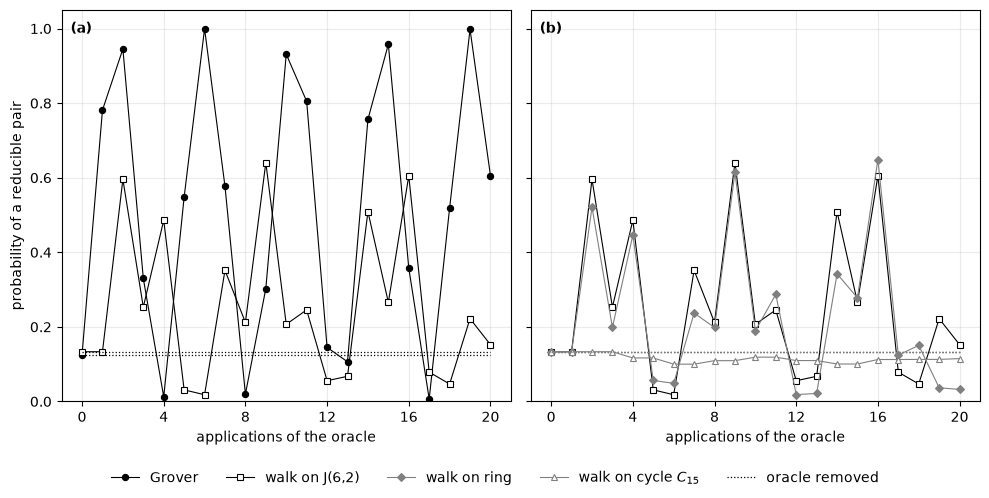

In [12]:
# This cell draws Fig. 1 of the paper. Panel (a) shows the same predicate realized by a global
# oracle (Grover) and by a local oracle (walk on J(6,2)). Both amplify the reducible pairs, but in
# different ways. Grover follows a regular oscillation, while the walk changes irregularly, because
# amplitude moves along the edges of the graph.

# Panel (b) shows the same local oracle on the three graphs. On the two graphs with 8 neighbours per
# pair the walk amplifies the reducible pairs, and on the poorly connected cycle it does not.

# Dotted lines show the evolutions with the oracle removed, which stay at their initial values. The
# figure is drawn in black and grey, with a different marker for every curve, as in the paper.

steps = np.arange(T_MAX + 1)
style = {   # colour, marker, marker face, label
    "Grover": ("black", "o", "black", "Grover"),
    "walk on Johnson graph J(6,2)": ("black", "s", "white", "walk on J(6,2)"),
    "walk on ring (8 neighbours)": ("0.5", "D", "0.5", "walk on ring"),
    "walk on cycle C_15": ("0.5", "^", "white", r"walk on cycle $C_{15}$"),
}
panels = [
    ("(a)", ["Grover", "walk on Johnson graph J(6,2)"]),
    ("(b)", ["walk on Johnson graph J(6,2)", "walk on ring (8 neighbours)", "walk on cycle C_15"]),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, (label, names) in zip(axes, panels):
    for name in names:
        colour, marker, face, _ = style[name]
        with_oracle, without_oracle = results[name]
        ax.plot(steps, with_oracle, "-", marker=marker, ms=4.5, mfc=face, mec=colour, mew=0.8,
                lw=0.8, color=colour)
        ax.plot(steps, without_oracle, ":", lw=0.9, color=colour)
    ax.set_xlabel("applications of the oracle")
    ax.set_xticks(range(0, T_MAX + 1, 4))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.text(0.02, 0.97, label, transform=ax.transAxes, va="top", fontweight="bold")
axes[0].set_ylabel("probability of a reducible pair")
handles = [Line2D([], [], color=c, marker=m, mfc=f, mec=c, mew=0.8, ms=4.5, lw=0.8, label=l)
           for c, m, f, l in style.values()]
handles.append(Line2D([], [], color="black", ls=":", lw=0.9, label="oracle removed"))
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

realization                                   with oracle         oracle removed
Grover                              3880 shots (0.947)   507 shots (0.124)
walk on Johnson graph J(6,2)        2471 shots (0.603)   570 shots (0.139)
walk on ring (8 neighbours)         2114 shots (0.516)   570 shots (0.139)
walk on cycle C_15                   570 shots (0.139)   570 shots (0.139)


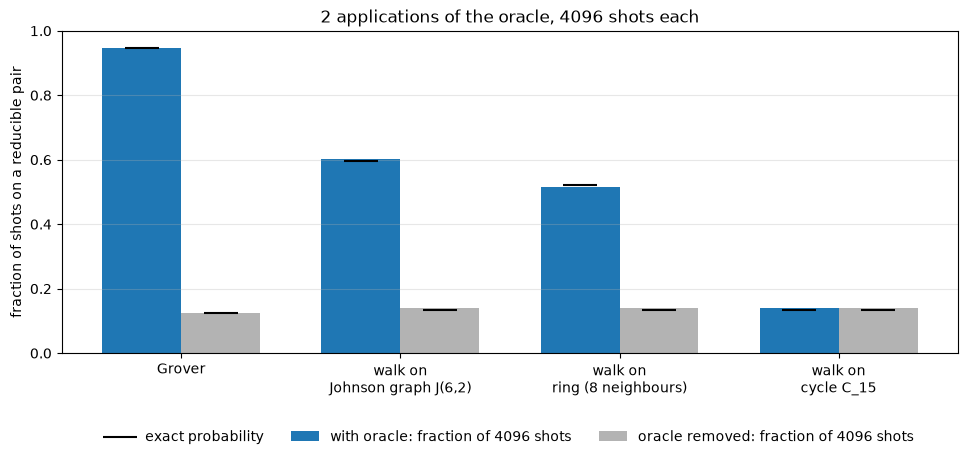

In [13]:
# Cells 10 and 12 use exact probabilities computed from the state vector of each circuit, that is,
# an ideal simulation of the quantum circuit. A quantum computer does not give probabilities. Each
# run of a circuit ends with a measurement that returns one basis state. This cell imitates that for
# all four realizations, as was done separately in Example 1 and Example 2. Each circuit is stopped
# after STEPS = 2 applications of the oracle (the optimal number of Grover iterations, and the first
# maximum of the walk on J(6,2)), all qubits are measured, and the circuit is run SHOTS = 4096
# times. The same is done with the oracle removed.

# The simulator is StatevectorSampler. It draws the measurement outcomes at random from the exact
# probabilities. Its random generator is started with SEED, so the counts below are reproducible.
# Qiskit reports each outcome as a bit string whose last qubits are written first. For Grover the
# whole bit string (4 qubits) is the pair index. For the walks its first four bits are the pair
# index and the remaining bits are the coin direction, which is ignored. A shot returns a reducible
# pair when its pair index is in M, and for Grover the padding state 15 counts as not reducible.

# Reading the result. For each realization the fraction of shots that return a reducible pair
# estimates the exact probability after 2 steps in the table of Cell 10. With 4096 shots the
# statistical uncertainty is at most sqrt(0.5 * 0.5 / 4096) = 0.008. In the bar chart the black
# marks show the exact probabilities.

# Repeated counts. The sampler starts its random generator again from SEED for every circuit it
# runs. Circuits whose measurement probabilities are the same therefore return the same counts. The
# three walks without the oracle, and the walk on the cycle with it, all have probability 2/15 of a
# reducible pair and all give 570 shots. For the same reason the counts of Grover and of the walk on
# J(6,2) are the same as in Example 1 and Example 2.

STEPS = 2
SHOTS = 4096

circuits = {}
for use_oracle in (True, False):
    circuits[("Grover", use_oracle)] = (
        grover_circuit(M, STEPS, use_oracle=use_oracle, measure=True), 0)
    for name, neighbours in GRAPHS.items():
        walk = Walk(neighbours, M if use_oracle else [])
        circuits[(f"walk on {name}", use_oracle)] = (
            walk.circuit(STEPS, measure=True), walk.n_coin)

sampler = StatevectorSampler(seed=SEED)
fractions = {}
print(f"{'realization':34s} {'with oracle':>22s} {'oracle removed':>22s}")
for name in results:
    line = f"{name:34s}"
    for use_oracle in (True, False):
        qc, n_coin = circuits[(name, use_oracle)]
        counts = sampler.run([qc], shots=SHOTS).result()[0].data.meas.get_counts()
        hits = sum(c for bits, c in counts.items() if int(bits[:N_POS], 2) in M)
        fractions[(name, use_oracle)] = hits / SHOTS
        line += f" {hits:5d} shots ({hits / SHOTS:.3f})"
    print(line)

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(results))
width = 0.36
for offset, use_oracle, label, colour in ((-width / 2, True, "with oracle", "C0"),
                                          (width / 2, False, "oracle removed", "0.7")):
    ax.bar(x + offset, [fractions[(name, use_oracle)] for name in results], width,
           color=colour, label=f"{label}: fraction of {SHOTS} shots")
    exact = [results[name][0 if use_oracle else 1][STEPS] for name in results]
    ax.scatter(x + offset, exact, marker="_", s=600, color="black", zorder=3,
               label="exact probability" if use_oracle else None)
ax.set_xticks(x)
ax.set_xticklabels([name.replace("walk on ", "walk on\n") for name in results])
ax.set_ylabel("fraction of shots on a reducible pair")
ax.set_ylim(0, 1)
ax.set_title(f"{STEPS} applications of the oracle, {SHOTS} shots each")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

In [14]:
# This comparison shows that all four realizations are quantum circuits, simulated both exactly and
# by sampling measurement outcomes, and that the two agree within the statistical uncertainty of the
# shots. The same sieving predicate, on the same pairs, can be realized by a global oracle (Grover)
# and by a local oracle (quantum walk), and in both cases the oracle alone produces the
# amplification, since without it nothing changes. The two realizations give different dynamics, a
# regular oscillation for Grover and an irregular evolution for the walk. The local oracle depends
# on the graph in which it is embedded. On the two well-connected graphs with 8 neighbours per pair
# (spectral gaps 0.75 and 0.55) it amplifies the reducible pairs, and on the poorly connected cycle
# (spectral gap 0.09) it does not. This is the dependence on delta that appears in Eq. (16).

# This comparison does not show anything about asymptotic speedups. With 15 candidate pairs no
# complexity statement can be made, and at this size Grover reaches a higher probability than any of
# the walks. Nor does it show that the Johnson graph is better than every other well-connected
# graph. At this size the ring, which has no meaning for sieving, behaves similarly, so what matters
# here is how well the graph is connected. It does not reproduce the algorithm of Chailloux and
# Loyer [6] either. Only their graph family is used.

# On the cycle the coin had to differ from the other graphs (Hadamard coin instead of Grover coin),
# because with 2 directions the Grover coin cannot produce interference at all. The ring, which has
# the same coin as J(6,2), shows that the contrast with the cycle is not due to the coin alone.